<p align="center">
  <img src="https://readme-typing-svg.herokuapp.com?font=Fira+Code&size=28&duration=3000&pause=1200&color=00F5FF&center=true&vCenter=true&width=700&lines=+Name+-+Satyam+Chandra;" alt="Typing SVG" />
</p>

<div style="background-color: #f8f9fa; padding: 25px; border-radius: 12px; border-left: 6px solid #4a90e2; box-shadow: 0 4px 6px rgba(0,0,0,0.05); font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; transition: transform 0.3s ease-in-out;" onmouseover="this.style.transform='translateY(-5px)'" onmouseout="this.style.transform='translateY(0)'">
    <h2 style="margin: 0; color: #2c3e50; font-size: 28px;">Satyam Chandra</h2>
    <p style="margin: 5px 0 20px 0; color: #7f8c8d; font-size: 16px; font-style: italic;">ML & DL Enthusiast</p>
    <div style="display: flex; gap: 15px; flex-wrap: wrap;">
        <a href="https://satyamchandra-info.vercel.app/" target="_blank" style="text-decoration: none; color: white; background-color: #1abc9c; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(26,188,156,0.3);">🌐 Portfolio</a>
        <a href="https://github.com/C0DER-B0T" target="_blank" style="text-decoration: none; color: white; background-color: #34495e; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(52,73,94,0.3);">🐙 GitHub</a>
        <a href="https://www.linkedin.com/in/satyam-chandra-953857356/" target="_blank" style="text-decoration: none; color: white; background-color: #0077b5; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(0,119,181,0.3);">💼 LinkedIn</a>
        <a href="mailto:chandrasatyam31@gmail.com" style="text-decoration: none; color: white; background-color: #e74c3c; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(231,76,60,0.3);">✉️ Email</a>
        <a href="https://pages.razorpay.com/coffeeforsatyam" target="_blank">
  <img src="https://cdn.buymeacoffee.com/buttons/v2/default-yellow.png" alt="Buy Me A Coffee" width="180">
</a>
    </div>
</div>

<center>
<h1>Capstone Project: Online Retail Analytics & Customer Segmentation</h1>
<p>Exploratory Data Analysis, RFM Modeling, and K-Means Clustering</p>
<hr>
</center>

### Step 1: Loading the Dataset
We load the Online Retail dataset. The dataset can be imported directly via the Google Drive link or loaded from the local repository directory if present.

In [1]:
import os
import pandas as pd

# The dataset is hosted on Google Drive (folder: https://drive.google.com/drive/u/0/folders/14wWJMYsD5ISyiZZ8xqvEK3rEGXdjGL6-)
# Direct download link fallback:
drive_url = "https://drive.google.com/uc?id=13b9qLXoEuGmLEQRO6-BO6Vu5fQ63iB2I&export=download"
local_file = "OnlineRetail.csv"

if os.path.exists(local_file):
    df = pd.read_csv(local_file, encoding="ISO-8859-1")
else:
    df = pd.read_csv(drive_url, encoding="ISO-8859-1")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


### Step 2: Checking Dataset Shape and Column Info
We inspect the dimensions and column data types to understand the structure of the data.

In [2]:
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
df.info()

Total Rows: 541909, Total Columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


### Step 3: Checking Missing Values and Duplicate Records
Identifying missing values across features, particularly CustomerID and Description.

In [3]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows count: {df.duplicated().sum()}")

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows count: 5268


### Step 4: Data Cleaning - Removing Missing IDs and Duplicates
Customer segmentation requires valid customer identifiers. We drop rows with missing CustomerID and drop exact duplicates.

In [4]:
df = df.dropna(subset=['CustomerID'])
df = df.drop_duplicates()
df['CustomerID'] = df['CustomerID'].astype(int)
print(f"Cleaned dataset shape: {df.shape}")

Cleaned dataset shape: (401604, 8)


### Step 5: Filtering Invalid Transactions
Transactions with negative Quantity represent cancellations or returns. We also remove records where UnitPrice is zero or negative.

In [5]:
# Filter out cancellations and zero/negative prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print(f"Active purchase transactions: {df.shape[0]}")

Active purchase transactions: 392692


### Step 6: Feature Engineering - Total Purchase Amount
Calculating total spend per line item as Quantity multiplied by UnitPrice.

In [6]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df[['Quantity', 'UnitPrice', 'TotalAmount']].head()

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


### Step 7: Parsing Invoice Date
Converting InvoiceDate to datetime format to enable time-based and recency analysis.

In [7]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(f"Date range from {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

Date range from 2010-12-01 08:26:00 to 2011-12-09 12:50:00


### Step 8: Top 10 Best Selling Products by Quantity Sold
Visualizing the most frequently purchased items across the retail store.

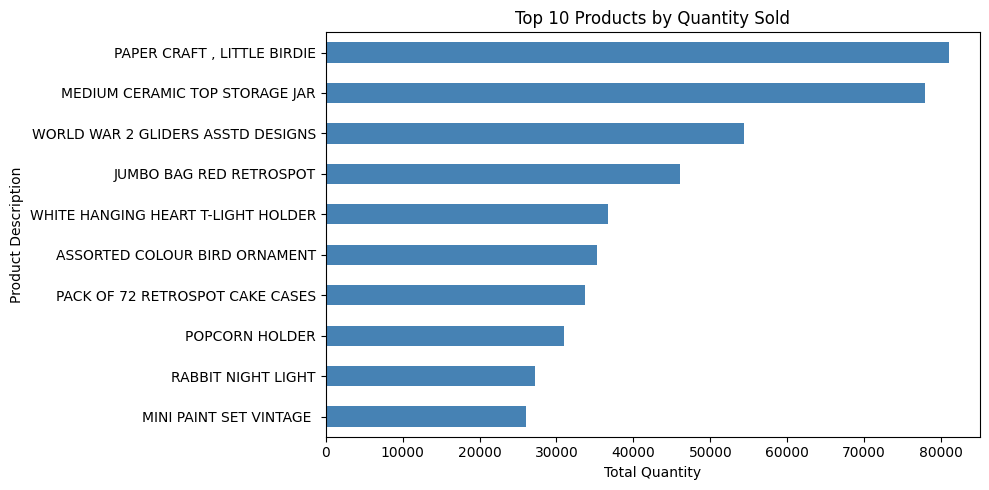

In [8]:
import matplotlib.pyplot as plt

top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_products.plot(kind='barh', color='steelblue')
plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Total Quantity')
plt.ylabel('Product Description')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Step 9: Top 10 Countries by Total Revenue
Checking the geographical distribution of sales revenue.

/tmp/ipykernel_4034/3878143658.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_rev.values, y=country_rev.index, palette='Blues_r')


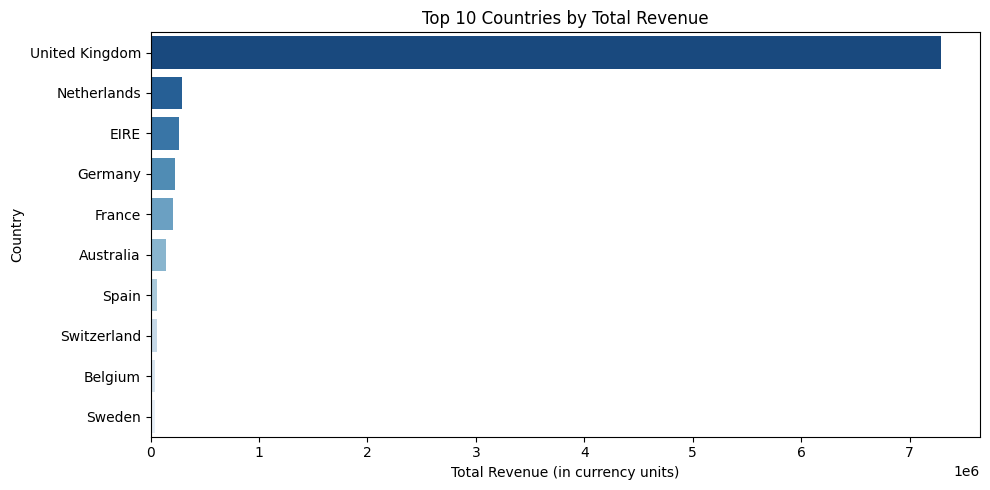

In [9]:
import seaborn as sns

country_rev = df.groupby('Country')['TotalAmount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=country_rev.values, y=country_rev.index, palette='Blues_r')
plt.title('Top 10 Countries by Total Revenue')
plt.xlabel('Total Revenue (in currency units)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

### Step 10: Monthly Sales Revenue Trend
Analyzing monthly sales to observe revenue seasonality and business growth over time.

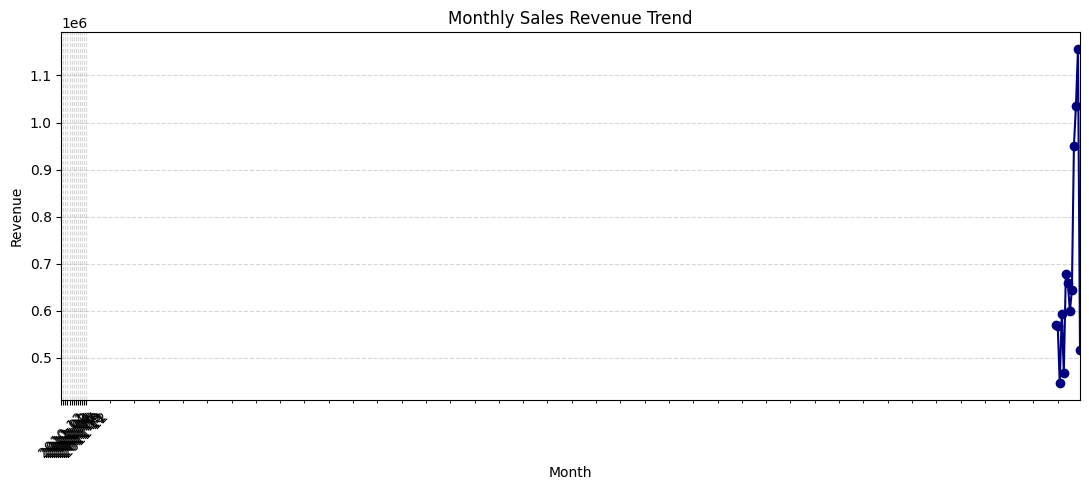

In [10]:
df['InvoiceYearMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly_sales = df.groupby('InvoiceYearMonth')['TotalAmount'].sum()

plt.figure(figsize=(11, 5))
monthly_sales.plot(kind='line', marker='o', color='navy')
plt.title('Monthly Sales Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(len(monthly_sales)), [str(x) for x in monthly_sales.index], rotation=45)
plt.tight_layout()
plt.show()

### Step 11: Constructing the RFM Table
Computing Recency, Frequency, and Monetary metrics for each individual customer:
- Recency: Days since the customer's last purchase relative to the snapshot date.
- Frequency: Count of distinct purchase transactions (invoices).
- Monetary: Total monetary expenditure by the customer.

In [11]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


### Step 12: RFM Summary Statistics and Distribution Check
Inspecting distributions and skewness in Recency, Frequency, and Monetary values.

In [12]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


### Step 13: Addressing Skewness with Log Transformation
RFM features typically display severe right-skewed distributions. We apply log transformation (log1p) to normalize distributions prior to distance-based clustering.

In [13]:
import numpy as np

rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].apply(np.log1p)
rfm_log.head()

,Recency,Frequency,Monetary
0,5.789960,0.693147,11.253955
1,1.098612,2.079442,8.368925
2,4.330733,1.609438,7.494564
3,2.995732,0.693147,7.472245
4,5.739793,0.693147,5.815324


### Step 14: Standardizing Features
Standardizing the log-transformed RFM features so that each feature has zero mean and unit variance.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
rfm_scaled_df.head()

,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.707716
1,-2.038734,1.074425,1.414903
2,0.373104,0.386304,0.720024
3,-0.623086,-0.955214,0.702287
4,1.424558,-0.955214,-0.614514


### Step 15: Finding Optimal Clusters using the Elbow Method
Running K-Means across k values from 1 to 8 and computing the Within-Cluster Sum of Squares (Inertia).

/tmp/ipykernel_4034/2145889864.py:12: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(K_range, inertia, 'bo-', color='teal')


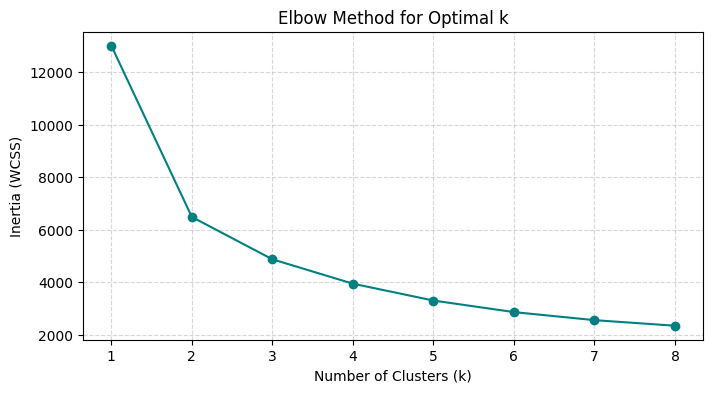

In [15]:
from sklearn.cluster import KMeans

inertia = []
K_range = range(1, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled_df)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, 'bo-', color='teal')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Step 16: Evaluating Silhouette Scores for Cluster Quality
Calculating Silhouette scores to validate clustering cohesion and separation for k = 2, 3, 4, 5.

In [16]:
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled_df)
    score = silhouette_score(rfm_scaled_df, labels)
    print(f"Silhouette Score for k={k}: {score:.4f}")

Silhouette Score for k=2: 0.4328
Silhouette Score for k=3: 0.3365
Silhouette Score for k=4: 0.3375
Silhouette Score for k=5: 0.3162


### Step 17: Training Final K-Means Model (k=4)
Fitting the final K-Means algorithm with 4 clusters and attaching cluster labels to our customer dataset.

In [17]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled_df)

print("Customer count per cluster:")
print(rfm['Cluster'].value_counts())

Customer count per cluster:
Cluster
1    1622
3    1166
2     837
0     713
Name: count, dtype: int64


### Step 18: Cluster Profiling - Average RFM Values
Analyzing the characteristics of each cluster by looking at the mean Recency, Frequency, and Monetary spend.

In [18]:
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

cluster_summary

Recency Frequency Monetary      
           mean      mean     mean count
Cluster                                 
0         12.17     13.75  8088.02   713
1        181.51      1.32   341.00  1622
2         17.70      2.19   557.32   837
3         71.64      4.08  1801.78  1166

### Step 19: Visualizing Customer Clusters
Visualizing clusters in a scatter plot of Recency versus Monetary spend.

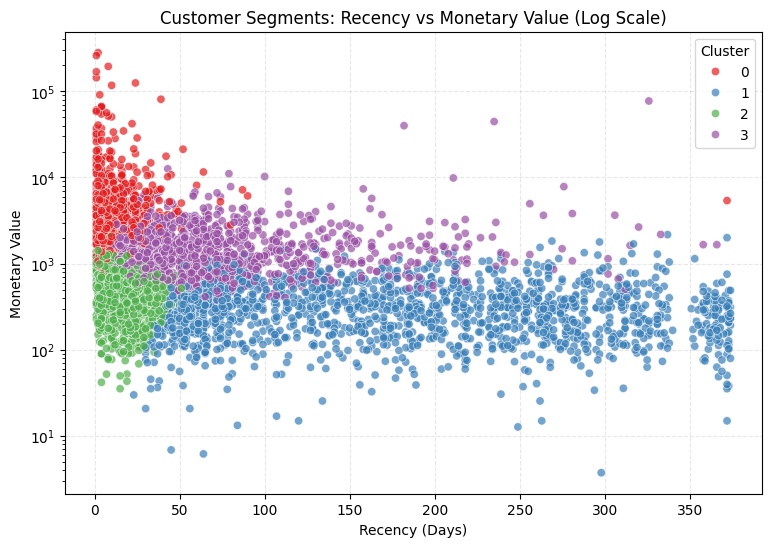

In [19]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x='Recency', 
    y='Monetary', 
    hue='Cluster', 
    data=rfm, 
    palette='Set1', 
    alpha=0.7
)
plt.yscale('log')
plt.title('Customer Segments: Recency vs Monetary Value (Log Scale)')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

### Step 20: Assigning Segment Names and Business Insights
Interpreting the clusters into actionable marketing cohorts:
- **Champions / High-Value Customers:** Low Recency, High Frequency, High Monetary spend. Reward with loyalty programs and early access.
- **Loyal / Regular Customers:** Moderate Recency, Good Frequency, Steady spend. Target with personalized cross-selling and up-selling.
- **Potential / Recent Customers:** Low Recency, Low Frequency, Moderate spend. Engage with welcome sequences and onboarding promotions.
- **At Risk / Churned Customers:** High Recency (long time since last visit), Low Frequency, Low spend. Re-engage with win-back campaigns and discounts.

In [20]:
# Profile cluster characteristics based on ranks
cluster_means = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

# Assign human-readable labels based on relative scores
def label_cluster(row):
    # Cluster with lowest recency and highest monetary
    if row['Recency'] < cluster_means['Recency'].mean() and row['Monetary'] >= cluster_means['Monetary'].median():
        return 'Champions / High Value'
    elif row['Recency'] < cluster_means['Recency'].mean():
        return 'Active / Potential'
    elif row['Monetary'] >= cluster_means['Monetary'].mean():
        return 'At Risk High Spenders'
    else:
        return 'Dormant / Churned'

rfm['Segment'] = rfm.apply(label_cluster, axis=1)
print(rfm['Segment'].value_counts())
rfm.head(10)

Segment
Dormant / Churned         1703
Active / Potential        1375
Champions / High Value    1193
At Risk High Spenders       67
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,At Risk High Spenders
1,12347,2,7,4310.00,0,Champions / High Value
2,12348,75,4,1797.24,3,Dormant / Churned
3,12349,19,1,1757.55,2,Champions / High Value
4,12350,310,1,334.40,1,Dormant / Churned
5,12352,36,8,2506.04,3,Champions / High Value
6,12353,204,1,89.00,1,Dormant / Churned
7,12354,232,1,1079.40,1,Dormant / Churned
8,12355,214,1,459.40,1,Dormant / Churned
9,12356,23,3,2811.43,3,Champions / High Value
